# 08. Mixed-domain fine-tuning and source retention

This experiment tests whether mixing PlantVillage with labeled PlantDoc training images retains more laboratory performance than field-only adaptation. Three completed runs start independently from the ResNet18 baseline, geometric ResNet18, and ViT-Small laboratory checkpoints.

Each epoch samples 185 Field Adapt Train and 185 Lab Train images in balanced batches. Field Dev macro-F1 selects checkpoints; Lab Validation is monitored without entering that rule. The original 47-image Field Test is accessed for contamination fingerprints, without model inference.

The mixed recipe approximates field-only optimizer-step counts but halves field-image exposure per epoch. It is not a matched field-exposure or measured compute comparison. Results describe development-set behavior, without independent field confirmation.

## Runtime and inputs

The saved runs use a Colab Tesla T4, timm `1.0.26`, and source revision `c28856e41a15a7b191909cfdeacb2c6c5934c8f7`. Existing verified manifests and laboratory checkpoints are required; split construction is separate from this experiment.

In [1]:
%pip install -q "timm==1.0.26" datasets pandas scikit-learn matplotlib pillow ImageHash

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.6/2.6 MB 68.7 MB/s eta 0:00:00:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 296.7/296.7 kB 24.4 MB/s eta 0:00:00


In [2]:
from pathlib import Path
import subprocess
import sys
import torch

assert torch.cuda.is_available(), "Select Runtime > Change runtime type > T4 GPU."
REPO_URL = "https://github.com/thutrang147/plant-disease-diagnosis.git"
PROJECT_ROOT = Path("/content/plant-disease-diagnosis")
if not PROJECT_ROOT.exists():
    subprocess.run(["git", "clone", "--depth", "1", REPO_URL, str(PROJECT_ROOT)], check=True)
else:
    subprocess.run(["git", "-C", str(PROJECT_ROOT), "pull", "--ff-only"], check=True)
GIT_SHA = subprocess.check_output(
    ["git", "-C", str(PROJECT_ROOT), "rev-parse", "HEAD"], text=True
).strip()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
print("Repository commit:", GIT_SHA)
print("GPU:", torch.cuda.get_device_name(0))

Repository commit: c28856e41a15a7b191909cfdeacb2c6c5934c8f7
GPU: Tesla T4


## Laboratory initializations

R1 loads the ResNet18 baseline, R2 loads geometric ResNet18, and V1 loads ViT-Small. All start from laboratory checkpoints rather than field-adapted states. Seed 42, two head epochs, up to six final-block epochs, and patience three are shared; batch sizes are 32 for ResNet18 and 16 for ViT.

In [3]:
from google.colab import drive
import gc
import hashlib
import json
import math
import random

import imagehash
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import timm
from PIL import Image
from sklearn.metrics import (
    accuracy_score, f1_score, classification_report,
    confusion_matrix, ConfusionMatrixDisplay,
)
from torch import nn
from torch.amp import GradScaler, autocast
from torch.utils.data import DataLoader, Subset
from torchvision import transforms
from torchvision.models import ResNet18_Weights, resnet18
from torchvision.transforms import InterpolationMode

from src.dataset import PlantDiseaseDataset

drive.mount("/content/drive")
SEED = 42
HEAD_EPOCHS = 2
LAST_BLOCK_EPOCHS = 6
EARLY_STOP_PATIENCE = 3
FIELD_SHARE = 0.5
# The field-only runs used all 370 Field images each epoch; with 50:50 mixing,
# this configuration samples 185 Field + 185 Lab per epoch (370 total).
NUM_WORKERS = 0
DEVICE = torch.device("cuda")
MODEL_NAME_VIT = "vit_small_patch16_224.augreg_in1k"
RUN_EXPERIMENTS = ["R1_resnet_baseline", "R2_resnet_geometric", "V1_vit_small"]

SPLITS_DIR = PROJECT_ROOT / "data" / "splits"
DRIVE_ROOT = Path("/content/drive/MyDrive/plant-disease-diagnosis")
OUTPUT_ROOT = DRIVE_ROOT / "mixed_domain_verified"
OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)
EXPERIMENTS = {
    "R1_resnet_baseline": {
        "architecture": "resnet18", "batch_size": 32,
        "checkpoint": DRIVE_ROOT / "resnet18_baseline/resnet18_lab_best.pt",
        "control_experiment": "A1_baseline",
    },
    "R2_resnet_geometric": {
        "architecture": "resnet18", "batch_size": 32,
        "checkpoint": DRIVE_ROOT / "resnet18_aug_geometric/resnet18_best.pt",
        "control_experiment": "A2_geometric",
    },
    "V1_vit_small": {
        "architecture": MODEL_NAME_VIT, "batch_size": 16,
        "checkpoint": DRIVE_ROOT / "vit_small_baseline/vit_small_lab_best.pt",
        "control_experiment": "V1_lab_baseline",
    },
}
assert RUN_EXPERIMENTS and len(set(RUN_EXPERIMENTS)) == len(RUN_EXPERIMENTS)
for name in RUN_EXPERIMENTS:
    assert name in EXPERIMENTS, f"Unknown experiment: {name}"
    assert EXPERIMENTS[name]["checkpoint"].is_file(), EXPERIMENTS[name]["checkpoint"]

label_map = json.loads((SPLITS_DIR / "label_map.json").read_text())
CLASS_NAMES = [name for name, idx in sorted(label_map.items(), key=lambda item: item[1])]
LABEL_IDS = list(range(5))
assert len(CLASS_NAMES) == 5 and sorted(label_map.values()) == LABEL_IDS

def reset_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

reset_seed()
print("timm:", timm.__version__)
print("Labels:", CLASS_NAMES)
print("Experiments:", RUN_EXPERIMENTS)

Mounted at /content/drive
timm: 1.0.26
Labels: ['Healthy', 'Early Blight', 'Late Blight', 'Bacterial Spot', 'Septoria Leaf Spot']
Experiments: ['R1_resnet_baseline', 'R2_resnet_geometric', 'V1_vit_small']


## Partition and provenance checks

The checks validate 370 Field Adapt Train, 92 Field Dev, 14 quarantine, 5,365 Lab Train, and 1,341 Lab Validation images. They verify labels and separation of the relevant row IDs, recorded exact hashes, and field groups. Manifest SHA-256 values associate the runs with their fixed partitions.

In [4]:
required_files = [
    "field_train.csv", "field_adapt_train.csv", "field_dev.csv",
    "field_test.csv", "field_quarantined_train.csv", "field_dev_protocol.json",
    "lab_train.csv", "lab_val.csv", "label_map.json",
]
for filename in required_files:
    assert (SPLITS_DIR / filename).is_file(), f"Missing {filename}; push verified manifests to GitHub."

protocol = json.loads((SPLITS_DIR / "field_dev_protocol.json").read_text())
assert protocol["strategy"].startswith("Perceptual pHash connected-component grouping")
assert protocol["phash_threshold"] == 4, "Unexpected pHash threshold; re-audit data if changed."

frames = {name: pd.read_csv(SPLITS_DIR / f"{name}.csv") for name in
          ("field_train", "field_adapt_train", "field_dev", "field_test",
           "field_quarantined_train", "lab_train", "lab_val")}
field_train, field_dev, lab_train, lab_val = (
    frames["field_adapt_train"], frames["field_dev"],
    frames["lab_train"], frames["lab_val"],
)
assert len(field_train) == protocol["adaptation_train_images"] == 370
assert len(field_dev) == protocol["development_images"] == 92
assert len(frames["field_test"]) == protocol["original_field_test_images_untouched"] == 47
assert len(frames["field_quarantined_train"]) == protocol["quarantined_total_train_images"] == 14
assert len(lab_train) == 5365 and len(lab_val) == 1341

for key, frame in frames.items():
    assert frame["row_id"].is_unique, f"Repeated source row_id in {key}"
    assert (frame["class_name"].map(label_map) == frame["label_id"]).all(), key
    assert (frame["source"] == ("plantvillage" if key.startswith("lab_") else "plantdoc")).all(), key
assert set(lab_train.row_id).isdisjoint(set(lab_val.row_id))
assert set(field_train.row_id).isdisjoint(set(field_dev.row_id))
assert set(field_train.group_id).isdisjoint(set(field_dev.group_id))
assert set(field_train.exact_hash).isdisjoint(set(field_dev.exact_hash))
assert set(field_train.group_id).isdisjoint(set(frames["field_quarantined_train"].group_id))
assert set(field_dev.group_id).isdisjoint(set(frames["field_quarantined_train"].group_id))
assert set(field_train.row_id).isdisjoint(set(frames["field_test"].row_id))
assert set(field_dev.row_id).isdisjoint(set(frames["field_test"].row_id))

MANIFEST_SHA256 = {
    key: hashlib.sha256((SPLITS_DIR / f"{key}.csv").read_bytes()).hexdigest()
    for key in ("field_adapt_train", "field_dev", "lab_train", "lab_val")
}
print("Field Adapt Train:", len(field_train), "| Field Dev:", len(field_dev))
print("Lab Train:", len(lab_train), "| Lab Val:", len(lab_val))
print("Field Dev SHA256:", MANIFEST_SHA256["field_dev"])
print("No manifest or group overlap across training/development partitions.")
display(pd.crosstab(
    pd.concat([field_train.assign(partition="adapt_train"),
               field_dev.assign(partition="dev")], ignore_index=True)["class_name"],
    pd.concat([field_train.assign(partition="adapt_train"),
               field_dev.assign(partition="dev")], ignore_index=True)["partition"],
))

Field Adapt Train: 370 | Field Dev: 92
Lab Train: 5365 | Lab Val: 1341
Field Dev SHA256: 2c61790f90214b3a4bbeb5e7f3e6228e6f2c013cab3cfe0b320a28a6aae960e9
No manifest or group overlap across training/development partitions.


partition,adapt_train,dev
class_name,,
Bacterial Spot,80,18
Early Blight,60,16
Healthy,44,11
Late Blight,79,20
Septoria Leaf Spot,107,27


## Image-content audit

The audit recomputes source-image fingerprints and checks stored content hashes and original labels. Saved exact/pHash candidate counts are zero across adaptation/development, adaptation/original-test, and development/original-test boundaries at Hamming distance ≤ 4. This screening does not establish that every related image has been identified.

In [5]:
# Load one manifest to reuse the PlantDoc Hugging Face source for the audit.
_audit_ds = PlantDiseaseDataset(SPLITS_DIR / "field_adapt_train.csv")
plantdoc_source = _audit_ds.source_datasets["plantdoc"]

def fingerprint(frame, name):
    fingerprints = []
    for row in frame.itertuples(index=False):
        sample = plantdoc_source[int(row.row_id)]
        assert sample["class_label"] == row.original_class, f"Source reorder: {name} row {row.row_id}"
        image = sample["image"].convert("RGB")
        digest = hashlib.sha256(f"{image.size}".encode() + image.tobytes()).hexdigest()
        if hasattr(row, "exact_hash"):
            assert digest == row.exact_hash, f"Image content drift in {name}, row {row.row_id}"
        fingerprints.append((digest, imagehash.phash(image)))
    return fingerprints

train_fps = fingerprint(field_train, "field_adapt_train")
dev_fps = fingerprint(field_dev, "field_dev")
test_fps = fingerprint(frames["field_test"], "field_test")
threshold = int(protocol["phash_threshold"])
def count_near(left, right):
    return sum(1 for h1, p1 in left for h2, p2 in right
               if h1 == h2 or p1 - p2 <= threshold)

counts = {
    "adapt_train / dev": count_near(train_fps, dev_fps),
    "adapt_train / original_test": count_near(train_fps, test_fps),
    "dev / original_test": count_near(dev_fps, test_fps),
}
print("Cross-partition exact/near-duplicate pairs:", counts)
assert not any(counts.values()), "Potential field data leakage: review split before training."
print("Image audit passed. No Field Test model inference was performed.")
del _audit_ds, plantdoc_source, train_fps, dev_fps, test_fps

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


README.md:   0%|          | 0.00/542 [00:00<?, ?B/s]

data/train-00000-of-00002.parquet: reconstructing file:   0%|          |  0.00B /  476MB            

data/train-00000-of-00002.parquet: downloading bytes:           |  0.00B            

data/train-00001-of-00002.parquet: reconstructing file:   0%|          |  0.00B /  516MB            

data/train-00001-of-00002.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/2578 [00:00<?, ? examples/s]

Cross-partition exact/near-duplicate pairs: {'adapt_train / dev': 0, 'adapt_train / original_test': 0, 'dev / original_test': 0}
Image audit passed. No Field Test model inference was performed.


## Balanced sampling and exposure control

Each epoch samples 185 distinct images per domain without replacement within that epoch; later epochs may reuse images. Batches contain 16 field plus 16 laboratory images for ResNet18, or eight plus eight for ViT; the final batch is smaller.

For each architecture, the 370 total images give approximately the field-only step budget. The recipe changes both domain composition and field exposure, so differences cannot be attributed to the domain ratio alone.

In [6]:
SAMPLES_PER_DOMAIN = math.ceil(len(field_train) * FIELD_SHARE)
assert SAMPLES_PER_DOMAIN == 185
assert 2 * SAMPLES_PER_DOMAIN == len(field_train)
assert SAMPLES_PER_DOMAIN <= len(lab_train)


def sample_domains(epoch_index):
    rng = np.random.default_rng(SEED + 1000 + epoch_index)
    field_ids = rng.choice(len(field_train), SAMPLES_PER_DOMAIN, replace=False).tolist()
    lab_ids = rng.choice(len(lab_train), SAMPLES_PER_DOMAIN, replace=False).tolist()
    assert len(set(field_ids)) == len(set(lab_ids)) == SAMPLES_PER_DOMAIN
    return field_ids, lab_ids

for epoch_index in (0, 1):
    fi, li = sample_domains(epoch_index)
    print(f"Epoch {epoch_index + 1}: {len(fi)} Field + {len(li)} Lab; "
          f"distinct Field images={len(set(fi))}")

Epoch 1: 185 Field + 185 Lab; distinct Field images=185
Epoch 2: 185 Field + 185 Lab; distinct Field images=185


## Preprocessing and model reconstruction

Each model restores its laboratory weights and original evaluation transform. ViT preprocessing is read from the source checkpoint. Architecture-specific training augmentation follows the earlier field-only recipe; Field Dev and Lab Validation remain deterministic.

In [7]:
def load_experiment(name):
    config = EXPERIMENTS[name]
    checkpoint_path = config["checkpoint"]
    ckpt = torch.load(checkpoint_path, map_location="cpu", weights_only=True)
    assert ckpt["class_names"] == CLASS_NAMES, f"Label mismatch for {name}"
    architecture = config["architecture"]
    if architecture == "resnet18":
        assert ckpt["architecture"] == "resnet18"
        assert ckpt.get("pretrained_weights") == "IMAGENET1K_V1"
        model = resnet18(weights=None)
        model.fc = nn.Linear(model.fc.in_features, 5)
        val_tf = ResNet18_Weights.IMAGENET1K_V1.transforms()
        mean, std = val_tf.mean, val_tf.std
        interp = InterpolationMode.BILINEAR
    else:
        assert architecture == MODEL_NAME_VIT
        assert ckpt["architecture"] == MODEL_NAME_VIT
        assert ckpt.get("pretrained_weights") == "augreg_in1k"
        data_cfg = ckpt["preprocessing_config"]
        assert tuple(data_cfg["input_size"]) == (3, 224, 224)
        model = timm.create_model(MODEL_NAME_VIT, pretrained=False, num_classes=5)
        val_tf = timm.data.create_transform(**data_cfg, is_training=False)
        mean, std = data_cfg["mean"], data_cfg["std"]
        interp = InterpolationMode.BICUBIC
    model.load_state_dict(ckpt["model_state_dict"], strict=True)
    train_tf = transforms.Compose([
        transforms.Resize(256, interpolation=interp),
        transforms.RandomResizedCrop(
            224, scale=(0.85, 1.0), ratio=(0.90, 1.10), interpolation=interp
        ),
        transforms.RandomHorizontalFlip(p=0.5),
        transforms.RandomApply([
            transforms.ColorJitter(brightness=0.10, contrast=0.10, saturation=0.10)
        ], p=0.35),
        transforms.ToTensor(),
        transforms.Normalize(mean=mean, std=std),
    ])
    return model.to(DEVICE), train_tf, val_tf, ckpt


def build_datasets(train_tf, val_tf, batch_size):
    datasets = {
        "field_train": PlantDiseaseDataset(SPLITS_DIR / "field_adapt_train.csv", transform=train_tf),
        "lab_train": PlantDiseaseDataset(SPLITS_DIR / "lab_train.csv", transform=train_tf),
        "field_dev": PlantDiseaseDataset(SPLITS_DIR / "field_dev.csv", transform=val_tf),
        "lab_val": PlantDiseaseDataset(SPLITS_DIR / "lab_val.csv", transform=val_tf),
    }
    loaders = {
        key: DataLoader(datasets[key], batch_size=batch_size, shuffle=False,
                        num_workers=NUM_WORKERS, pin_memory=True)
        for key in ("field_dev", "lab_val")
    }
    return datasets, loaders

## Optimization and selection

The source checkpoint is the initial candidate. Stage 1 updates the head; stage 2 updates ResNet18 `layer4 + fc` or ViT's last block, final normalization, and head, beginning from the best candidate. Field Dev macro-F1 controls selection and final-block early stopping.

ResNet18 BatchNorm statistics remain fixed; ViT uses mixed precision. Lab Validation is recorded each epoch and after reloading the selected state, but is not used by the checkpoint-selection condition.

In [8]:
def set_trainable(model, architecture, stage):
    if architecture == "resnet18":
        for name, p in model.named_parameters():
            p.requires_grad = (name.startswith("fc.") if stage == "head"
                               else name.startswith("fc.") or name.startswith("layer4."))
    else:
        last_prefix = f"blocks.{len(model.blocks) - 1}."
        for name, p in model.named_parameters():
            p.requires_grad = (name.startswith("head.") if stage == "head"
                               else name.startswith("head.")
                               or name.startswith(last_prefix)
                               or name.startswith("norm.")
                               or name.startswith("fc_norm."))
    assert any(p.requires_grad for p in model.parameters())


def make_optimizer(model, architecture, stage):
    if architecture == "resnet18":
        if stage == "head":
            return torch.optim.AdamW(model.fc.parameters(), lr=1e-4, weight_decay=1e-4)
        return torch.optim.AdamW([
            {"params": model.layer4.parameters(), "lr": 1e-5},
            {"params": model.fc.parameters(), "lr": 1e-4},
        ], weight_decay=1e-4)
    if stage == "head":
        return torch.optim.AdamW(model.get_classifier().parameters(), lr=1e-4,
                                 weight_decay=1e-4)
    head_ids = {id(p) for p in model.get_classifier().parameters()}
    backbone = [p for p in model.parameters() if p.requires_grad and id(p) not in head_ids]
    assert backbone
    return torch.optim.AdamW([
        {"params": backbone, "lr": 1e-5},
        {"params": model.get_classifier().parameters(), "lr": 1e-4},
    ], weight_decay=1e-4)


def calc_metrics(true, predicted, loss_total, n):
    return {
        "loss": float(loss_total) / n,
        "accuracy": float(accuracy_score(true, predicted)),
        "macro_f1": float(f1_score(true, predicted, labels=LABEL_IDS,
                                   average="macro", zero_division=0)),
    }


def evaluate(model, loader, use_amp, return_predictions=False):
    model.eval()
    y_true, y_pred, conf = [], [], []
    loss_total = 0.0
    criterion = nn.CrossEntropyLoss()
    with torch.inference_mode():
        for x, y in loader:
            x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True)
            with autocast("cuda", dtype=torch.float16, enabled=use_amp):
                logits = model(x)
            loss = criterion(logits.float(), y)
            prob, pred = torch.softmax(logits.float(), dim=1).max(dim=1)
            loss_total += float(loss.detach()) * len(y)
            y_true.extend(y.cpu().tolist())
            y_pred.extend(pred.cpu().tolist())
            conf.extend(prob.cpu().tolist())
    result = calc_metrics(y_true, y_pred, loss_total, len(loader.dataset))
    if return_predictions:
        return result, np.asarray(y_true), np.asarray(y_pred), np.asarray(conf)
    return result


def train_mixed_epoch(model, architecture, datasets, optimizer, scaler,
                      epoch_index, batch_size):
    half = batch_size // 2
    field_ids, lab_ids = sample_domains(epoch_index)
    field_loader = DataLoader(Subset(datasets["field_train"], field_ids),
                              batch_size=half, shuffle=True, num_workers=NUM_WORKERS,
                              pin_memory=True)
    lab_loader = DataLoader(Subset(datasets["lab_train"], lab_ids),
                            batch_size=half, shuffle=True, num_workers=NUM_WORKERS,
                            pin_memory=True)
    assert len(field_loader) == len(lab_loader)
    model.train()
    if architecture == "resnet18":
        # Preserve the previous adaptation protocol: do not update BN statistics.
        for module in model.modules():
            if isinstance(module, nn.modules.batchnorm._BatchNorm):
                module.eval()
    loss_total, n = 0.0, 0
    field_truth, field_pred, lab_truth, lab_pred = [], [], [], []
    for (fx, fy), (lx, ly) in zip(field_loader, lab_loader):
        x = torch.cat((fx, lx), dim=0).to(DEVICE, non_blocking=True)
        y = torch.cat((fy, ly), dim=0).to(DEVICE, non_blocking=True)
        permutation = torch.randperm(len(y), device=DEVICE)
        optimizer.zero_grad(set_to_none=True)
        with autocast("cuda", dtype=torch.float16, enabled=(architecture != "resnet18")):
            logits = model(x[permutation])
            loss = nn.functional.cross_entropy(logits.float(), y[permutation])
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
        # Undo shuffling so per-domain training diagnostics are interpretable.
        predictions = torch.empty_like(y)
        predictions[permutation] = logits.detach().argmax(dim=1)
        nf = len(fy)
        field_truth.extend(y[:nf].cpu().tolist())
        field_pred.extend(predictions[:nf].cpu().tolist())
        lab_truth.extend(y[nf:].cpu().tolist())
        lab_pred.extend(predictions[nf:].cpu().tolist())
        loss_total += float(loss.detach()) * len(y)
        n += len(y)
    assert n == 2 * SAMPLES_PER_DOMAIN
    return {
        "train_loss": loss_total / n,
        "train_field_macro_f1": float(f1_score(field_truth, field_pred,
                                              labels=LABEL_IDS, average="macro", zero_division=0)),
        "train_lab_macro_f1": float(f1_score(lab_truth, lab_pred,
                                            labels=LABEL_IDS, average="macro", zero_division=0)),
        "train_images": n,
    }

## Saved mixed-domain runs

All three selected checkpoints occur at final-block epoch 6. R1 achieves Field Dev macro-F1 0.3523 and Lab Validation macro-F1 0.9556; R2 achieves 0.4459 and 0.9223; V1 achieves 0.3872 and 0.9901. Histories and selected-state predictions are written under `mixed_domain_verified/<experiment>/` in Drive.


 R1_resnet_baseline


README.md:   0%|          | 0.00/5.86k [00:00<?, ?B/s]

data/train-00000-of-00002.parquet: reconstructing file:   0%|          |  0.00B /  402MB            

data/train-00000-of-00002.parquet: downloading bytes:           |  0.00B            

data/train-00001-of-00002.parquet: reconstructing file:   0%|          |  0.00B /  453MB            

data/train-00001-of-00002.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/54304 [00:00<?, ? examples/s]

head 1/2: Field Dev F1=0.2420 | Lab Val F1=0.9842 | best Field=0.2420
head 2/2: Field Dev F1=0.2483 | Lab Val F1=0.9851 | best Field=0.2483
last_block 1/6: Field Dev F1=0.2077 | Lab Val F1=0.9328 | best Field=0.2483
last_block 2/6: Field Dev F1=0.2782 | Lab Val F1=0.9151 | best Field=0.2782
last_block 3/6: Field Dev F1=0.3079 | Lab Val F1=0.9293 | best Field=0.3079
last_block 4/6: Field Dev F1=0.3406 | Lab Val F1=0.9423 | best Field=0.3406
last_block 5/6: Field Dev F1=0.3362 | Lab Val F1=0.9441 | best Field=0.3406
last_block 6/6: Field Dev F1=0.3523 | Lab Val F1=0.9556 | best Field=0.3523


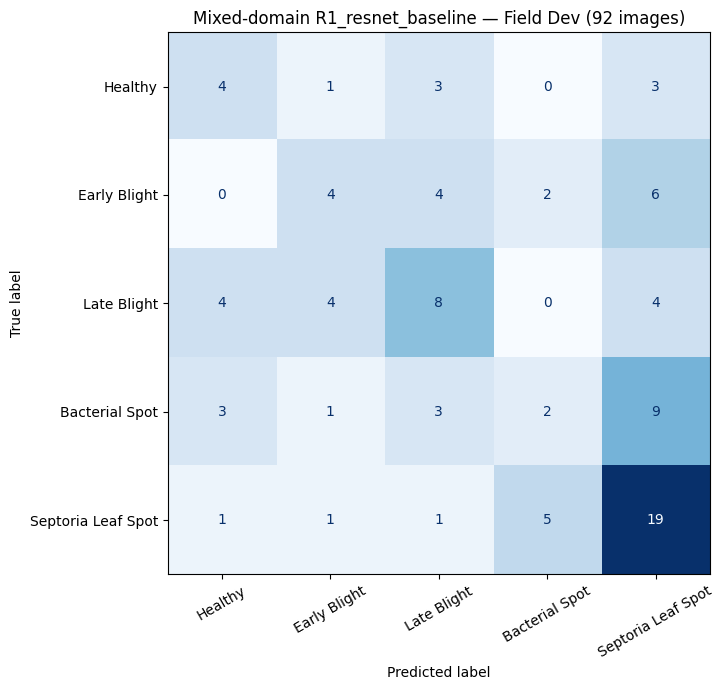

Selected: last_block epoch 6
Field Dev F1: 0.2355 -> 0.3523
Lab Val F1:   0.9879 -> 0.9556
Checkpoint: /content/drive/MyDrive/plant-disease-diagnosis/mixed_domain_verified/R1_resnet_baseline/mixed_domain_best.pt


,experiment,architecture,field_dev_images,lab_val_images,before_field_dev_accuracy,after_field_dev_accuracy,before_field_dev_macro_f1,after_field_dev_macro_f1,delta_field_dev_macro_f1,before_lab_val_macro_f1,after_lab_val_macro_f1,delta_lab_val_macro_f1,selected_phase,selected_epoch,field_dev_sha256,lab_val_sha256,source_checkpoint_sha256
0,R1_resnet_baseline,resnet18,92,1341,0.3261,0.4022,0.2355,0.3523,0.1168,0.9879,0.9556,-0.0323,last_block,6,2c61790f90214b3a4bbeb5e7f3e6228e6f2c013cab3cfe...,1a8bd3f22de052ab615a12940f4a687fecda7d0cff6dcb...,65d53766258f26cb505cce4c319c3f783cb0f3c6ef4608...



 R2_resnet_geometric
head 1/2: Field Dev F1=0.2497 | Lab Val F1=0.9695 | best Field=0.2497
head 2/2: Field Dev F1=0.2654 | Lab Val F1=0.9668 | best Field=0.2654
last_block 1/6: Field Dev F1=0.3023 | Lab Val F1=0.8591 | best Field=0.3023
last_block 2/6: Field Dev F1=0.3490 | Lab Val F1=0.8326 | best Field=0.3490
last_block 3/6: Field Dev F1=0.3236 | Lab Val F1=0.8400 | best Field=0.3490
last_block 4/6: Field Dev F1=0.4065 | Lab Val F1=0.8646 | best Field=0.4065
last_block 5/6: Field Dev F1=0.3920 | Lab Val F1=0.8949 | best Field=0.4065
last_block 6/6: Field Dev F1=0.4459 | Lab Val F1=0.9223 | best Field=0.4459


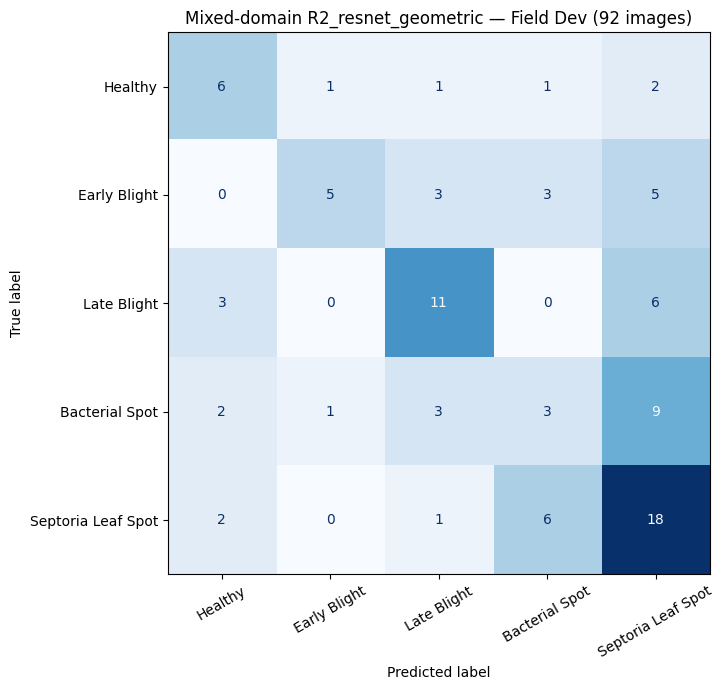

Selected: last_block epoch 6
Field Dev F1: 0.2497 -> 0.4459
Lab Val F1:   0.9753 -> 0.9223
Checkpoint: /content/drive/MyDrive/plant-disease-diagnosis/mixed_domain_verified/R2_resnet_geometric/mixed_domain_best.pt


,experiment,architecture,field_dev_images,lab_val_images,before_field_dev_accuracy,after_field_dev_accuracy,before_field_dev_macro_f1,after_field_dev_macro_f1,delta_field_dev_macro_f1,before_lab_val_macro_f1,after_lab_val_macro_f1,delta_lab_val_macro_f1,selected_phase,selected_epoch,field_dev_sha256,lab_val_sha256,source_checkpoint_sha256
0,R1_resnet_baseline,resnet18,92,1341,0.3261,0.4022,0.2355,0.3523,0.1168,0.9879,0.9556,-0.0323,last_block,6,2c61790f90214b3a4bbeb5e7f3e6228e6f2c013cab3cfe...,1a8bd3f22de052ab615a12940f4a687fecda7d0cff6dcb...,65d53766258f26cb505cce4c319c3f783cb0f3c6ef4608...
1,R2_resnet_geometric,resnet18,92,1341,0.3478,0.4674,0.2497,0.4459,0.1963,0.9753,0.9223,-0.0531,last_block,6,2c61790f90214b3a4bbeb5e7f3e6228e6f2c013cab3cfe...,1a8bd3f22de052ab615a12940f4a687fecda7d0cff6dcb...,51266f98875ba67402c547a43d78247f2e2d0fd08f1612...



 V1_vit_small
head 1/2: Field Dev F1=0.3043 | Lab Val F1=0.9957 | best Field=0.3043
head 2/2: Field Dev F1=0.3269 | Lab Val F1=0.9957 | best Field=0.3269
last_block 1/6: Field Dev F1=0.3124 | Lab Val F1=0.9944 | best Field=0.3269
last_block 2/6: Field Dev F1=0.3348 | Lab Val F1=0.9906 | best Field=0.3348
last_block 3/6: Field Dev F1=0.3650 | Lab Val F1=0.9892 | best Field=0.3650
last_block 4/6: Field Dev F1=0.3500 | Lab Val F1=0.9901 | best Field=0.3650
last_block 5/6: Field Dev F1=0.3717 | Lab Val F1=0.9911 | best Field=0.3717
last_block 6/6: Field Dev F1=0.3872 | Lab Val F1=0.9901 | best Field=0.3872


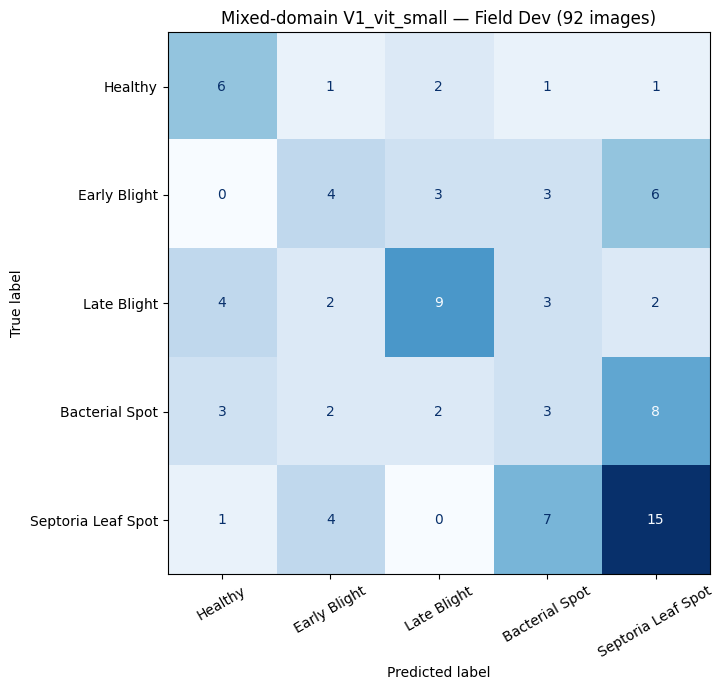

Selected: last_block epoch 6
Field Dev F1: 0.2677 -> 0.3872
Lab Val F1:   0.9966 -> 0.9901
Checkpoint: /content/drive/MyDrive/plant-disease-diagnosis/mixed_domain_verified/V1_vit_small/mixed_domain_best.pt


,experiment,architecture,field_dev_images,lab_val_images,before_field_dev_accuracy,after_field_dev_accuracy,before_field_dev_macro_f1,after_field_dev_macro_f1,delta_field_dev_macro_f1,before_lab_val_macro_f1,after_lab_val_macro_f1,delta_lab_val_macro_f1,selected_phase,selected_epoch,field_dev_sha256,lab_val_sha256,source_checkpoint_sha256
0,R1_resnet_baseline,resnet18,92,1341,0.3261,0.4022,0.2355,0.3523,0.1168,0.9879,0.9556,-0.0323,last_block,6,2c61790f90214b3a4bbeb5e7f3e6228e6f2c013cab3cfe...,1a8bd3f22de052ab615a12940f4a687fecda7d0cff6dcb...,65d53766258f26cb505cce4c319c3f783cb0f3c6ef4608...
1,R2_resnet_geometric,resnet18,92,1341,0.3478,0.4674,0.2497,0.4459,0.1963,0.9753,0.9223,-0.0531,last_block,6,2c61790f90214b3a4bbeb5e7f3e6228e6f2c013cab3cfe...,1a8bd3f22de052ab615a12940f4a687fecda7d0cff6dcb...,51266f98875ba67402c547a43d78247f2e2d0fd08f1612...
2,V1_vit_small,vit_small_patch16_224.augreg_in1k,92,1341,0.4022,0.4022,0.2677,0.3872,0.1194,0.9966,0.9901,-0.0065,last_block,6,2c61790f90214b3a4bbeb5e7f3e6228e6f2c013cab3cfe...,1a8bd3f22de052ab615a12940f4a687fecda7d0cff6dcb...,42c26a8aa70311d9504d55dda422f20e2ea5f0a5878f59...


Completed: 3 experiment(s).


In [9]:
def sha256_file(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()


def save_best(path, model, name, config, source_digest, stage, epoch, score):
    payload = {
        "model_state_dict": model.state_dict(),
        "architecture": config["architecture"],
        "class_names": CLASS_NAMES,
        "experiment": name,
        "adaptation_type": "balanced_mixed_domain",
        "source_checkpoint": str(config["checkpoint"]),
        "source_checkpoint_sha256": source_digest,
        "selected_phase": stage,
        "selected_epoch": int(epoch),
        "best_field_dev_macro_f1": float(score),
        "seed": SEED,
        "git_commit": GIT_SHA,
        "manifest_sha256": MANIFEST_SHA256,
        "field_dev_sha256": MANIFEST_SHA256["field_dev"],
        "per_epoch_samples_per_domain": SAMPLES_PER_DOMAIN,
        "field_sample_fraction": FIELD_SHARE,
        "head_epochs": HEAD_EPOCHS,
        "last_block_epochs": LAST_BLOCK_EPOCHS,
        "model_selection": "field_dev_macro_f1",
    }
    torch.save(payload, path)


def run_experiment(name):
    print("\n" + "=" * 55 + "\n", name)
    reset_seed()
    config = EXPERIMENTS[name]
    architecture = config["architecture"]
    use_amp = architecture != "resnet18"
    output_dir = OUTPUT_ROOT / name
    output_dir.mkdir(parents=True, exist_ok=True)
    best_path = output_dir / "mixed_domain_best.pt"
    hist_path = output_dir / "training_history.csv"
    source_digest = sha256_file(config["checkpoint"])

    model, train_tf, val_tf, source_checkpoint = load_experiment(name)
    datasets, loaders = build_datasets(train_tf, val_tf, config["batch_size"])
    # Prevent silent dataset drift after CSV schema or source dataset changes.
    assert datasets["field_train"].metadata.row_id.tolist() == field_train.row_id.tolist()
    assert datasets["lab_train"].metadata.row_id.tolist() == lab_train.row_id.tolist()
    before_field = evaluate(model, loaders["field_dev"], use_amp)
    before_lab = evaluate(model, loaders["lab_val"], use_amp)
    best_f1 = before_field["macro_f1"]
    best_phase, best_epoch = "source_unadapted", 0
    save_best(best_path, model, name, config, source_digest, best_phase, best_epoch, best_f1)
    history = [{
        "phase": "source_unadapted", "epoch": 0,
        "train_loss": np.nan, "train_field_macro_f1": np.nan,
        "train_lab_macro_f1": np.nan,
        "dev_accuracy": before_field["accuracy"],
        "dev_macro_f1": before_field["macro_f1"],
        "lab_val_accuracy": before_lab["accuracy"],
        "lab_val_macro_f1": before_lab["macro_f1"],
    }]
    global_epoch = 0
    scaler = GradScaler("cuda", enabled=use_amp)
    for stage, max_epochs in (("head", HEAD_EPOCHS), ("last_block", LAST_BLOCK_EPOCHS)):
        if stage == "last_block":
            selected = torch.load(best_path, map_location="cpu", weights_only=True)
            model.load_state_dict(selected["model_state_dict"], strict=True)
        set_trainable(model, architecture, stage)
        optimizer = make_optimizer(model, architecture, stage)
        patience = 0
        for epoch in range(1, max_epochs + 1):
            train_result = train_mixed_epoch(
                model, architecture, datasets, optimizer, scaler,
                epoch_index=global_epoch, batch_size=config["batch_size"]
            )
            global_epoch += 1
            dev_result = evaluate(model, loaders["field_dev"], use_amp)
            lab_result = evaluate(model, loaders["lab_val"], use_amp)
            history.append({
                "phase": stage, "epoch": epoch,
                **train_result,
                "dev_accuracy": dev_result["accuracy"],
                "dev_macro_f1": dev_result["macro_f1"],
                "lab_val_accuracy": lab_result["accuracy"],
                "lab_val_macro_f1": lab_result["macro_f1"],
            })
            pd.DataFrame(history).to_csv(hist_path, index=False)
            if dev_result["macro_f1"] > best_f1 + 1e-6:
                best_f1 = dev_result["macro_f1"]
                best_phase, best_epoch = stage, epoch
                save_best(best_path, model, name, config, source_digest,
                          best_phase, best_epoch, best_f1)
                patience = 0
            else:
                patience += 1
            print(f"{stage} {epoch}/{max_epochs}: Field Dev F1={dev_result['macro_f1']:.4f} | "
                  f"Lab Val F1={lab_result['macro_f1']:.4f} | best Field={best_f1:.4f}")
            if stage == "last_block" and patience >= EARLY_STOP_PATIENCE:
                print("Early stopping: no better Field Dev macro-F1")
                break

    # Reload the best checkpoint rather than evaluating the final epoch.
    checkpoint = torch.load(best_path, map_location="cpu", weights_only=True)
    assert checkpoint["field_dev_sha256"] == MANIFEST_SHA256["field_dev"]
    assert checkpoint["source_checkpoint_sha256"] == source_digest
    model.load_state_dict(checkpoint["model_state_dict"], strict=True)
    after_field, truth, pred, conf = evaluate(
        model, loaders["field_dev"], use_amp, return_predictions=True
    )
    after_lab = evaluate(model, loaders["lab_val"], use_amp)
    assert np.isclose(after_field["macro_f1"], best_f1, atol=1e-9)
    report = classification_report(
        truth, pred, target_names=CLASS_NAMES, labels=LABEL_IDS,
        zero_division=0, digits=4,
    )
    (output_dir / "field_dev_classification_report.txt").write_text(report, encoding="utf-8")
    results = field_dev[["source", "row_id", "class_name", "label_id"]].copy()
    results["predicted_label_id"] = pred
    results["predicted_class"] = [CLASS_NAMES[int(i)] for i in pred]
    results["confidence"] = conf
    results["correct"] = pred == truth
    results.to_csv(output_dir / "field_dev_predictions.csv", index=False)

    matrix = confusion_matrix(truth, pred, labels=LABEL_IDS)
    fig, ax = plt.subplots(figsize=(8.6, 7))
    ConfusionMatrixDisplay(matrix, display_labels=CLASS_NAMES).plot(
        ax=ax, cmap="Blues", colorbar=False, xticks_rotation=30
    )
    ax.set_title(f"Mixed-domain {name} — Field Dev ({len(field_dev)} images)")
    fig.tight_layout()
    fig.savefig(output_dir / "field_dev_confusion_matrix.png", dpi=160)
    plt.show()
    plt.close(fig)

    pd.DataFrame(history).to_csv(hist_path, index=False)
    print("Selected:", best_phase, "epoch", best_epoch)
    print(f"Field Dev F1: {before_field['macro_f1']:.4f} -> {after_field['macro_f1']:.4f}")
    print(f"Lab Val F1:   {before_lab['macro_f1']:.4f} -> {after_lab['macro_f1']:.4f}")
    print("Checkpoint:", best_path)
    row = {
        "experiment": name,
        "architecture": architecture,
        "field_dev_images": len(field_dev),
        "lab_val_images": len(lab_val),
        "before_field_dev_accuracy": before_field["accuracy"],
        "after_field_dev_accuracy": after_field["accuracy"],
        "before_field_dev_macro_f1": before_field["macro_f1"],
        "after_field_dev_macro_f1": after_field["macro_f1"],
        "delta_field_dev_macro_f1": after_field["macro_f1"] - before_field["macro_f1"],
        "before_lab_val_macro_f1": before_lab["macro_f1"],
        "after_lab_val_macro_f1": after_lab["macro_f1"],
        "delta_lab_val_macro_f1": after_lab["macro_f1"] - before_lab["macro_f1"],
        "selected_phase": best_phase,
        "selected_epoch": best_epoch,
        "field_dev_sha256": MANIFEST_SHA256["field_dev"],
        "lab_val_sha256": MANIFEST_SHA256["lab_val"],
        "source_checkpoint_sha256": source_digest,
        "checkpoint": str(best_path),
    }
    # Free up GPU memory before loading another architecture.
    del model, datasets, loaders, optimizer, source_checkpoint, checkpoint
    gc.collect()
    torch.cuda.empty_cache()
    return row

summary_rows = []
for experiment_name in RUN_EXPERIMENTS:
    row = run_experiment(experiment_name)
    summary_rows.append(row)
    partial_summary = pd.DataFrame(summary_rows)
    partial_summary.to_csv(OUTPUT_ROOT / "mixed_domain_summary.csv", index=False)
    display(partial_summary.drop(columns="checkpoint").round(4))

print("Completed:", len(summary_rows), "experiment(s).")

## Field-only controls

The comparison reads the completed field-only summaries only when their checkpoints carry the same Field Dev manifest hash. Initial architecture, source checkpoint, and split are matched by experiment; domain composition and field exposure differ.

| Initialization | Field-only Field Dev macro-F1 | Mixed Field Dev macro-F1 | Field-only Lab Validation macro-F1 | Mixed Lab Validation macro-F1 |
| --- | ---: | ---: | ---: | ---: |
| R1 baseline ResNet18 | 0.4119 | 0.3523 | 0.8185 | 0.9556 |
| R2 geometric ResNet18 | 0.4347 | 0.4459 | 0.7668 | 0.9223 |
| V1 ViT-Small | 0.3838 | 0.3872 | 0.9892 | 0.9901 |

In [10]:
CONTROL_SPEC = [
    ("R1_resnet_baseline", "ResNet18 field-only A1",
     DRIVE_ROOT / "field_adaptation_verified/adaptation_summary.csv",
     DRIVE_ROOT / "field_adaptation_verified/A1_baseline/resnet18_field_best.pt",
     "A1_baseline"),
    ("R2_resnet_geometric", "ResNet18 field-only A2",
     DRIVE_ROOT / "field_adaptation_verified/adaptation_summary.csv",
     DRIVE_ROOT / "field_adaptation_verified/A2_geometric/resnet18_field_best.pt",
     "A2_geometric"),
    ("V1_vit_small", "ViT-Small field-only V1",
     DRIVE_ROOT / "vit_small_field_adaptation_verified/adaptation_summary.csv",
     DRIVE_ROOT / "vit_small_field_adaptation_verified/V1_lab_baseline/vit_small_field_best.pt",
     "V1_lab_baseline"),
]
controls = []
for exp_key, label, summary_path, ckpt_path, exp_id in CONTROL_SPEC:
    if not summary_path.is_file() or not ckpt_path.is_file():
        print("Missing verified control:", label)
        continue
    checkpoint = torch.load(ckpt_path, map_location="cpu", weights_only=True)
    if checkpoint.get("field_dev_sha256") != MANIFEST_SHA256["field_dev"]:
        print("SKIPPED: Field Dev split mismatch for", label)
        continue
    tab = pd.read_csv(summary_path)
    match = tab.loc[tab["experiment"] == exp_id]
    if len(match) != 1:
        print("SKIPPED: summary not uniquely matched for", label)
        continue
    ref = match.iloc[0]
    controls.append({
        "experiment": exp_key, "setting": "field_only", "label": label,
        "field_dev_macro_f1": float(ref["after_field_dev_macro_f1"]),
        "lab_val_macro_f1": float(ref["after_lab_val_macro_f1"]),
    })

mixed = pd.DataFrame([{
    "experiment": row["experiment"], "setting": "mixed_50_50",
    "label": row["experiment"],
    "field_dev_macro_f1": row["after_field_dev_macro_f1"],
    "lab_val_macro_f1": row["after_lab_val_macro_f1"],
} for row in summary_rows])
comparison = pd.concat([pd.DataFrame(controls), mixed], ignore_index=True)
comparison.to_csv(OUTPUT_ROOT / "mixed_vs_field_only.csv", index=False)
display(comparison.round(4))
if len(controls) < len(RUN_EXPERIMENTS):
    print("Some verified controls are unavailable. Cross-setting comparisons are incomplete.")

,experiment,setting,label,field_dev_macro_f1,lab_val_macro_f1
0,R1_resnet_baseline,field_only,ResNet18 field-only A1,0.4119,0.8185
1,R2_resnet_geometric,field_only,ResNet18 field-only A2,0.4347,0.7668
2,V1_vit_small,field_only,ViT-Small field-only V1,0.3838,0.9892
3,R1_resnet_baseline,mixed_50_50,R1_resnet_baseline,0.3523,0.9556
4,R2_resnet_geometric,mixed_50_50,R2_resnet_geometric,0.4459,0.9223
5,V1_vit_small,mixed_50_50,V1_vit_small,0.3872,0.9901


## Source retention and target performance

Mixing retains higher Lab Validation macro-F1 than the corresponding field-only run for all three initializations. Field Dev macro-F1 is lower for R1 and slightly higher for R2 and V1. The plots describe these trade-offs; no repeated-run variability or measured compute comparison is available.

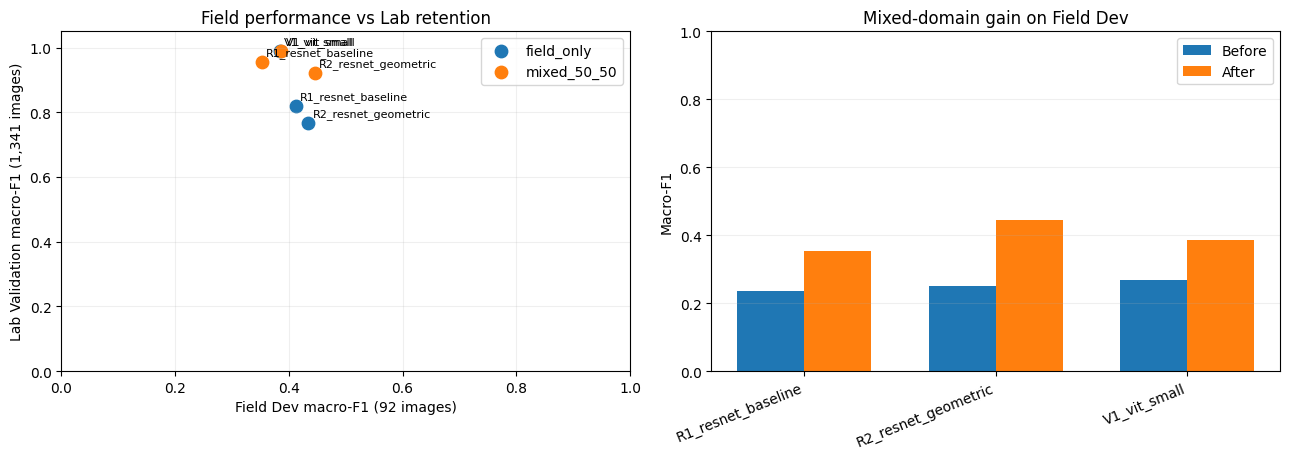

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.7))
for key, frame in comparison.groupby("setting"):
    axes[0].scatter(frame["field_dev_macro_f1"], frame["lab_val_macro_f1"],
                    label=key, s=80)
    for row in frame.itertuples():
        axes[0].annotate(row.experiment, (row.field_dev_macro_f1, row.lab_val_macro_f1),
                         xytext=(3, 5), textcoords="offset points", fontsize=8)
axes[0].set_title("Field performance vs Lab retention")
axes[0].set_xlabel("Field Dev macro-F1 (92 images)")
axes[0].set_ylabel("Lab Validation macro-F1 (1,341 images)")
axes[0].set_xlim(0, 1)
axes[0].set_ylim(0, 1.05)
axes[0].grid(alpha=0.2)
axes[0].legend()

summary = pd.DataFrame(summary_rows)
positions = np.arange(len(summary))
width = 0.35
axes[1].bar(positions - width/2, summary["before_field_dev_macro_f1"],
            width, label="Before")
axes[1].bar(positions + width/2, summary["after_field_dev_macro_f1"],
            width, label="After")
axes[1].set_xticks(positions, summary["experiment"], rotation=22, ha="right")
axes[1].set_ylabel("Macro-F1")
axes[1].set_title("Mixed-domain gain on Field Dev")
axes[1].set_ylim(0, 1)
axes[1].legend()
axes[1].grid(axis="y", alpha=0.2)
fig.tight_layout()
fig.savefig(OUTPUT_ROOT / "mixed_domain_comparison.png", dpi=160)
plt.show()
plt.close(fig)

## Class-level Field Dev recall

Selected mixed checkpoints have nonzero Healthy and Bacterial Spot recall, unlike the laboratory baselines. R2 and V1 each recognize 6/11 Healthy and 3/18 Bacterial Spot images. R2 has higher recall than V1 on Early Blight (5/16 versus 4/16), Late Blight (11/20 versus 9/20), and Septoria Leaf Spot (18/27 versus 15/27).

In [12]:
per_class_rows = []
for row in summary_rows:
    pred_path = OUTPUT_ROOT / row["experiment"] / "field_dev_predictions.csv"
    predictions = pd.read_csv(pred_path)
    assert predictions.row_id.tolist() == field_dev.row_id.tolist()
    report = classification_report(
        predictions["label_id"], predictions["predicted_label_id"],
        target_names=CLASS_NAMES, labels=LABEL_IDS, output_dict=True, zero_division=0,
    )
    for disease in CLASS_NAMES:
        per_class_rows.append({
            "experiment": row["experiment"], "class_name": disease,
            "support": int(report[disease]["support"]),
            "recall": float(report[disease]["recall"]),
            "f1": float(report[disease]["f1-score"]),
        })
per_class = pd.DataFrame(per_class_rows)
per_class.to_csv(OUTPUT_ROOT / "mixed_domain_per_class.csv", index=False)
display(per_class.pivot(index="class_name", columns="experiment", values="recall").round(4))

experiment,R1_resnet_baseline,R2_resnet_geometric,V1_vit_small
class_name,,,
Bacterial Spot,0.1111,0.1667,0.1667
Early Blight,0.2500,0.3125,0.2500
Healthy,0.3636,0.5455,0.5455
Late Blight,0.4000,0.5500,0.4500
Septoria Leaf Spot,0.7037,0.6667,0.5556


## Results and interpretation

All three mixed runs improve Field Dev macro-F1 over their laboratory source checkpoints: R1 0.2355 → 0.3523, R2 0.2497 → 0.4459, and V1 0.2677 → 0.3872. Mixing retains more laboratory performance than the field-only controls, but R1's field score declines relative to field-only adaptation. R2 has the highest mixed Field Dev score; V1 retains the highest laboratory score.

These single-seed, Field Dev-selected results support a source-retention trade-off for the recorded recipes, not a causal claim about architecture or sampling ratio. The 92 development images are small and imbalanced; no new independent field test is recorded. Notebook 09 compares four fixed checkpoints on Lab Test and Field Dev, and notebook 10 examines their errors.